# 03 · Análise dos resultados
Resultados no teste, decomposição do original ao corrigido e backtest. Relatório completo em `docs/relatorio_final.md`.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for sub in ("data", "targets", "features", "validation"):
    sys.path.insert(0, str(ROOT / "src" / sub))
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
TAB = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
import json, glob

## Métricas no teste com intervalo de confiança (bootstrap em blocos)

,model,metric,point,ci_low,ci_high,n_runs,p_auc_le_0.5
0,Perceptron,auc,0.410,0.234,0.605,1,0.859
1,Perceptron,brier,0.194,0.111,0.286,1,NaN
2,Perceptron,f1,0.173,0.065,0.283,1,NaN
3,Random Forest,auc,0.543,0.397,0.688,5,0.272
4,Random Forest,brier,0.168,0.105,0.238,5,NaN
5,Random Forest,f1,0.343,0.199,0.478,5,NaN
6,LSTM,auc,0.544,0.426,0.642,5,0.245
7,LSTM,brier,0.172,0.097,0.254,5,NaN
8,LSTM,f1,0.343,0.199,0.478,5,NaN


,diff,point,ci_low,ci_high
0,AUC Random Forest − Perceptron,0.133,0.009,0.269
1,AUC LSTM − Perceptron,0.134,-0.030,0.296
2,AUC LSTM − Random Forest,0.001,-0.121,0.115


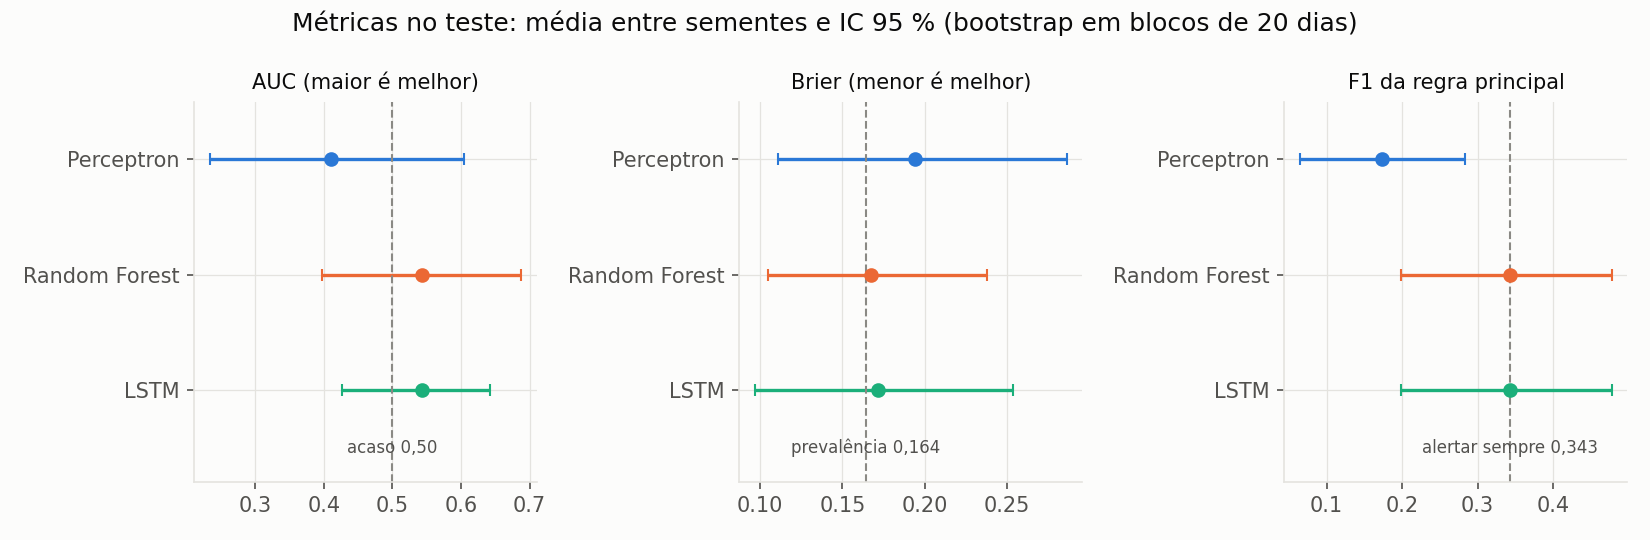

In [2]:
ci = pd.read_csv(TAB / 'phase8_metrics_ci.csv'); display(ci.round(3))
display(pd.read_csv(TAB / 'phase8_pairwise_auc.csv').round(3))
display(Image(str(FIG / 'metrics_with_ci.png')))

## Decomposição: de onde vem a diferença para a monografia
AUC médio por passo (S0 = código original literal; S1 troca o alvo).

In [3]:
ab = pd.DataFrame([json.load(open(p, encoding='utf-8')) for p in sorted(glob.glob(str(ROOT/'outputs'/'metrics'/'ablation_cache'/'*.json')))])
ab['auc_rep'] = ab['auc_cal'].fillna(ab['auc'])
ab.pivot_table(index='step', columns='kind', values='auc_rep', aggfunc='mean').round(3)

kind,lstm,perceptron,rf
step,,,
S0_original,0.778,0.661,0.757
S1_alvo,0.610,0.400,0.546
S2_scaler,0.514,0.408,0.548
S3_variaveis,0.561,0.402,0.535
S4_purge,0.592,0.410,0.582
S5_crossfit,0.592,0.410,0.582


## Figuras do teste

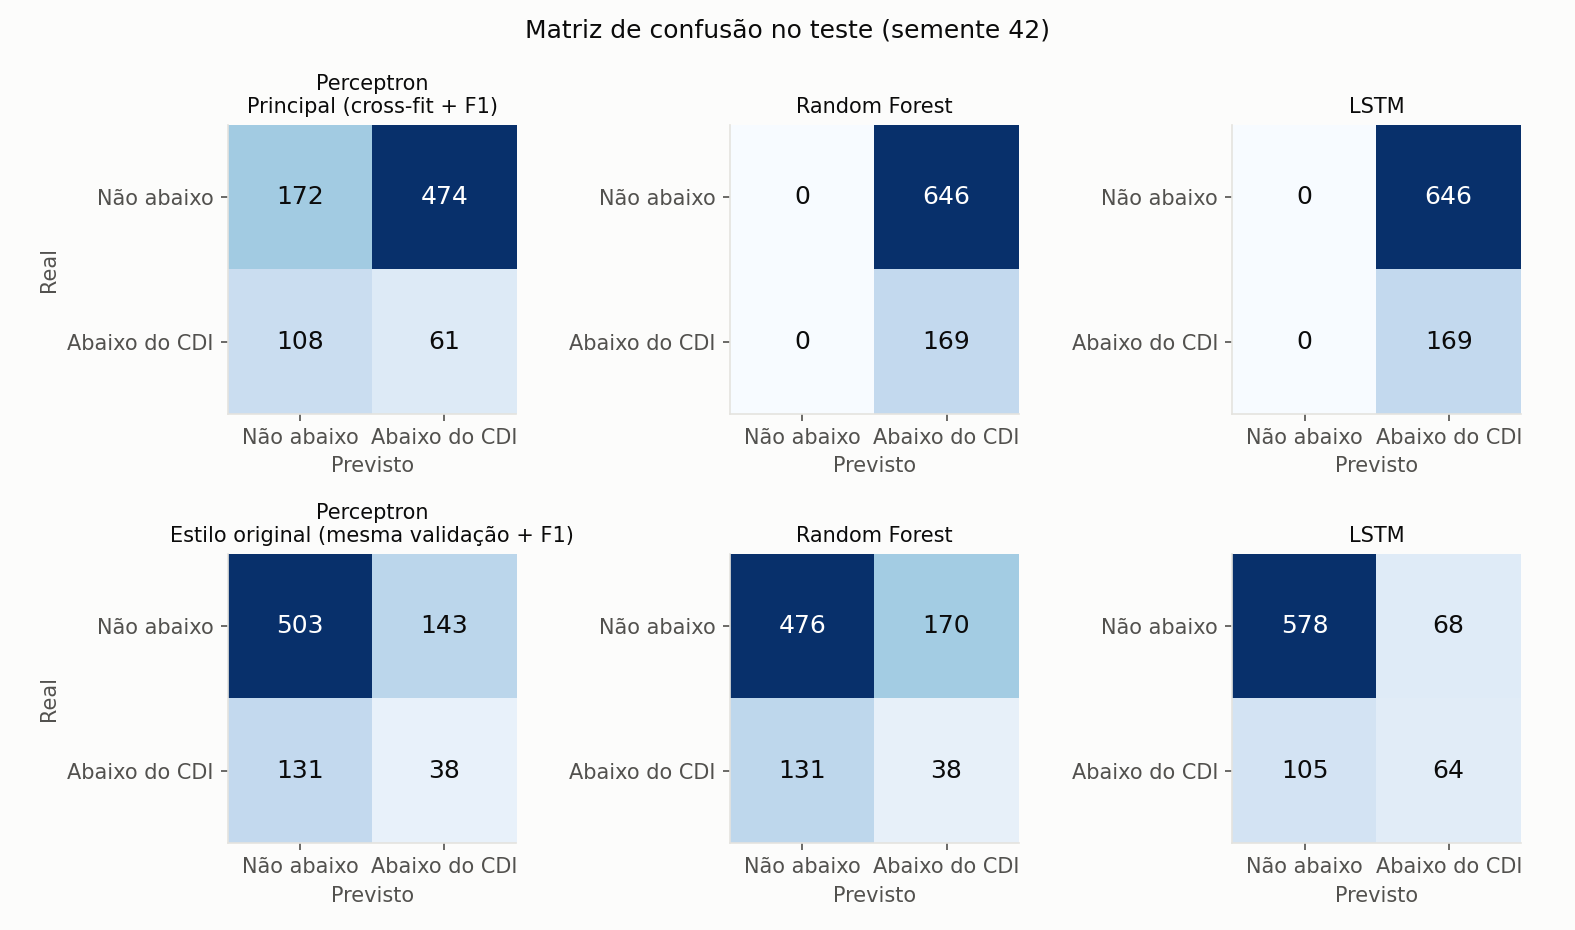

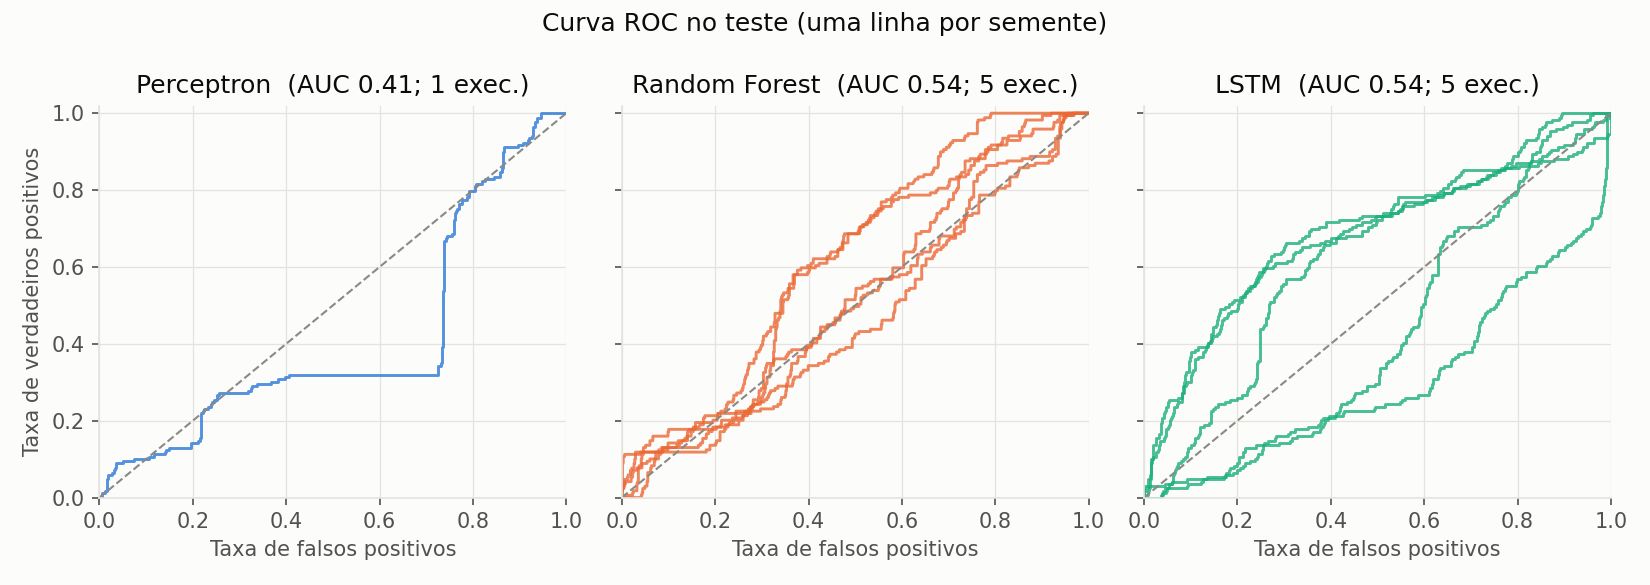

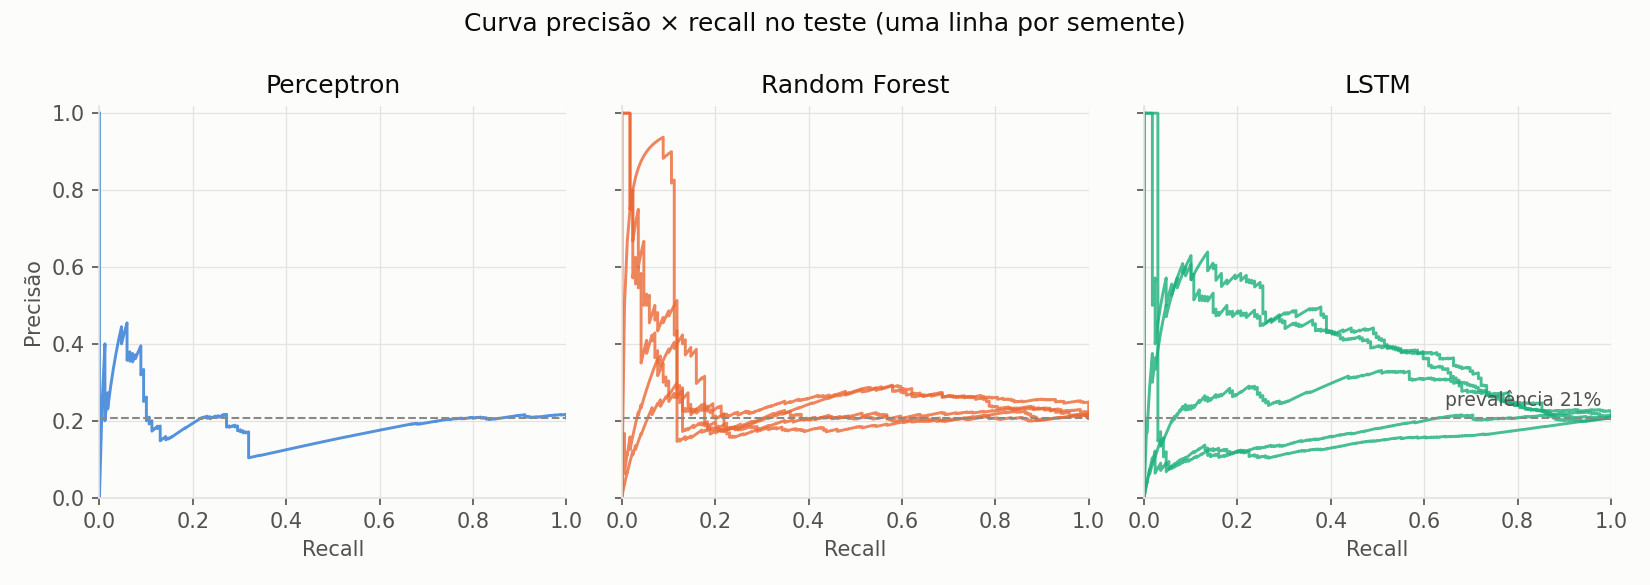

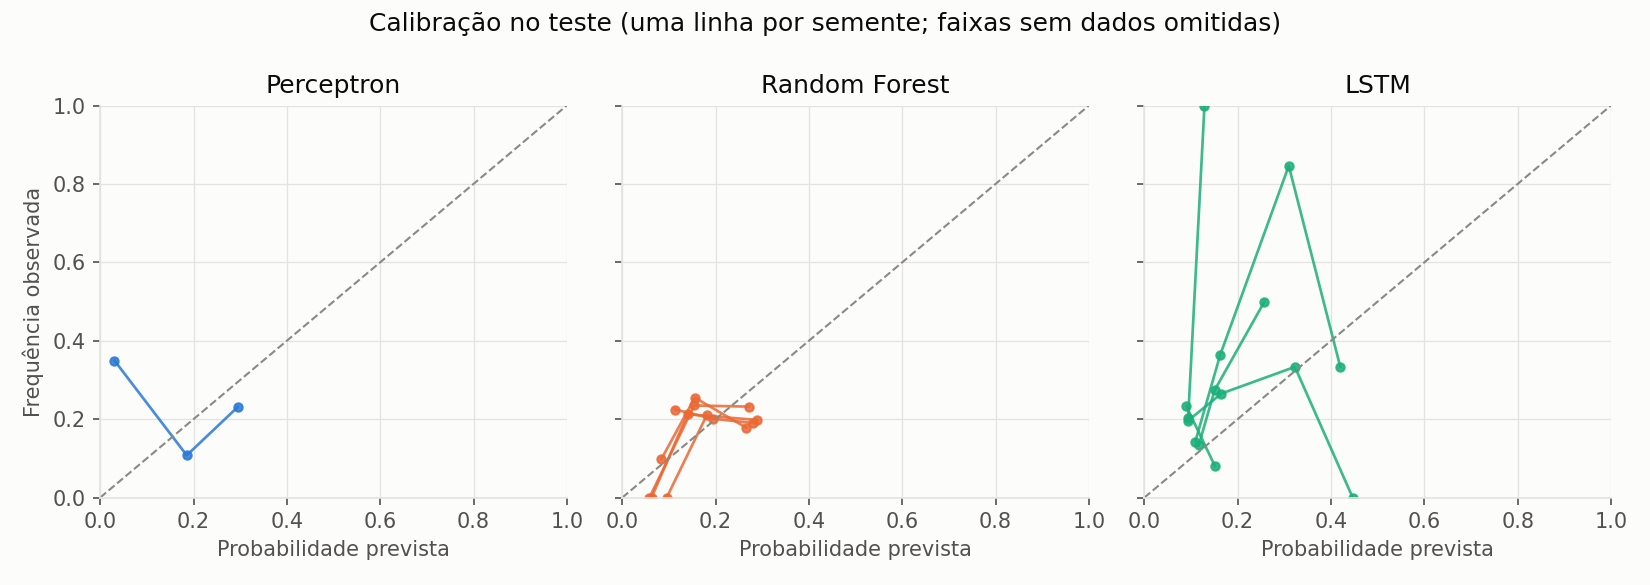

In [4]:
for f in ['confusion_counts.png', 'roc_curve.png', 'pr_curve.png', 'calibration_curve.png']:
    display(Image(str(FIG / f)))

## Backtest (só o período de teste)

,tipo,regra,custo_bps,final_media,final_min,final_max,anual_media,vol_media,mdd_media,exc_cdi_media,exc_ida_media,trocas_media,dias_cdi,n
0,lstm,estilo_original,0,155.215,153.299,157.541,0.146,0.007,-0.011,0.016,0.003,9.6,0.096,5
3,lstm,principal,0,147.557,147.557,147.557,0.128,0.001,0.000,0.000,-0.013,1.0,1.000,5
6,lstm,valor,0,153.831,153.768,153.872,0.142,0.008,-0.012,0.013,-0.000,1.2,0.005,5
9,perceptron,estilo_original,0,153.690,153.690,153.690,0.142,0.006,-0.006,0.013,-0.000,24.0,0.222,1
12,perceptron,principal,0,145.619,145.619,145.619,0.123,0.004,-0.006,-0.004,-0.017,10.0,0.656,1
15,perceptron,valor,0,153.872,153.872,153.872,0.143,0.008,-0.012,0.013,0.000,0.0,0.000,1
18,rf,estilo_original,0,151.785,149.660,152.516,0.138,0.005,-0.004,0.009,-0.004,31.8,0.426,5
21,rf,principal,0,147.557,147.557,147.557,0.128,0.001,0.000,0.000,-0.013,1.0,1.000,5
24,rf,valor,0,153.872,153.872,153.872,0.143,0.008,-0.012,0.013,0.000,0.0,0.000,5


,final_base100,retorno_total,retorno_anual,vol_anual,max_drawdown,excesso_vs_cdi_anual,excesso_vs_ida_anual,trocas,dias_no_cdi,n_dias
IDA (comprar e manter),153.872,0.539,0.143,0.008,-0.012,0.013,0.000,0.0,0.0,815.0
CDI 100 %,147.557,0.476,0.128,0.001,0.000,0.000,-0.013,0.0,1.0,815.0
IDA pelo nível do índice (alternativa),152.553,0.526,0.140,0.008,-0.012,0.010,-0.003,0.0,0.0,815.0


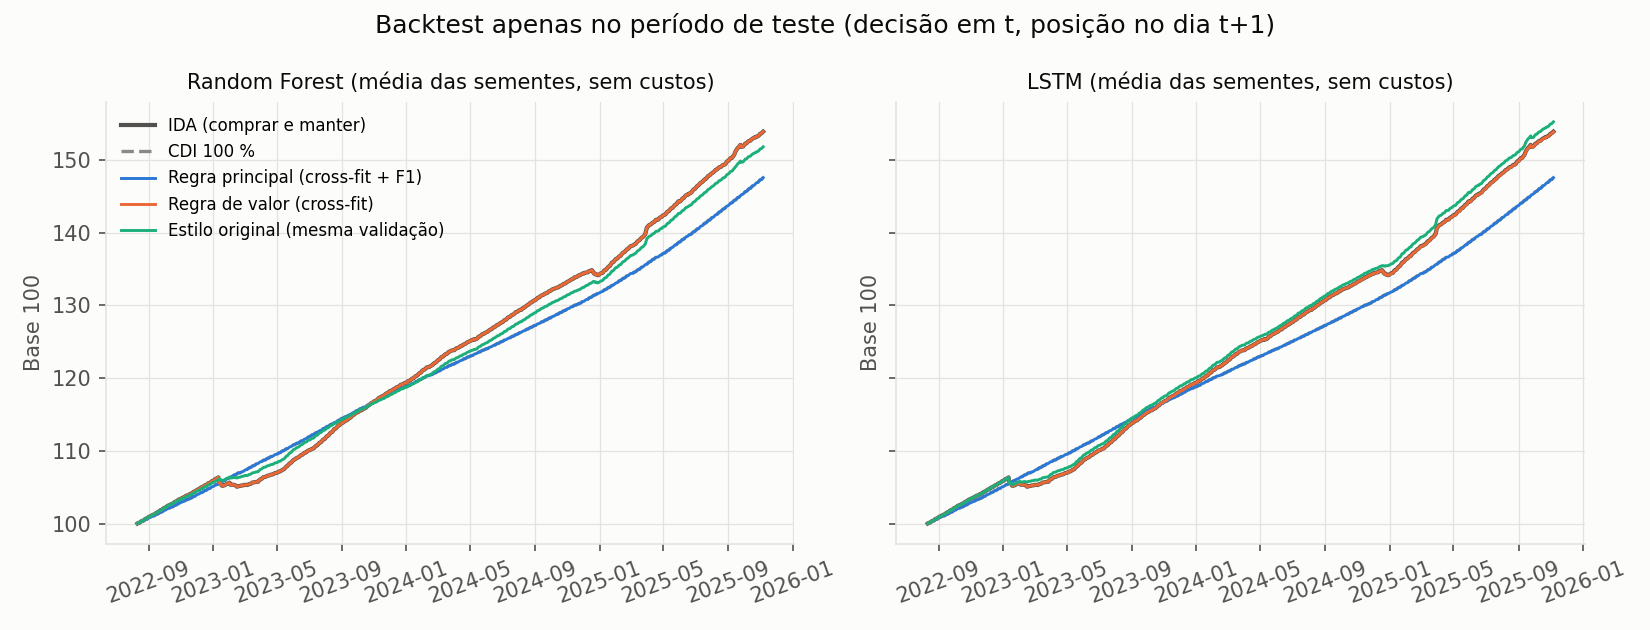

In [5]:
s = pd.read_csv(TAB / 'phase9_backtest_summary.csv')
display(s[s.custo_bps == 0].round(3))
display(pd.read_csv(TAB / 'phase9_benchmarks.csv', index_col=0).round(3))
display(Image(str(FIG / 'backtest_curves.png')))

## Backtest original da monografia, por trecho
O ganho sobre o IDA vem em boa parte da validação (usada para escolher o limiar).

,modelo,trecho,dias,estrategia_base100,ida_base100,cdi_base100,ganho_vs_ida_pp,ganho_vs_cdi_pp,taxa_alerta,trocas
0,Random Forest,período inteiro (como na monografia),4071,570.898,534.118,443.402,6.886,28.754,0.250,123.0
1,Random Forest,treino (in-sample),2442,287.910,285.917,253.014,0.697,13.792,0.078,18.0
2,Random Forest,validação (usada para limiar),814,128.394,121.403,118.772,5.759,8.102,0.477,46.0
3,Random Forest,teste original (fora da amostra),815,154.439,153.874,147.551,0.367,4.668,0.539,59.0
4,Random Forest,conferência: série Excel x recálculo,4071,570.898,NaN,NaN,NaN,NaN,570.898,NaN
5,LSTM,período inteiro (como na monografia),4071,572.836,534.118,443.402,7.249,29.191,0.191,96.0
6,LSTM,treino (in-sample),2442,282.857,285.917,253.014,-1.070,11.795,0.201,57.0
7,LSTM,validação (usada para limiar),814,128.222,121.403,118.772,5.616,7.957,0.278,34.0
8,LSTM,teste original (fora da amostra),815,157.943,153.874,147.551,2.644,7.044,0.077,6.0
9,LSTM,conferência: série Excel x recálculo,4071,572.836,NaN,NaN,NaN,NaN,5.728,NaN


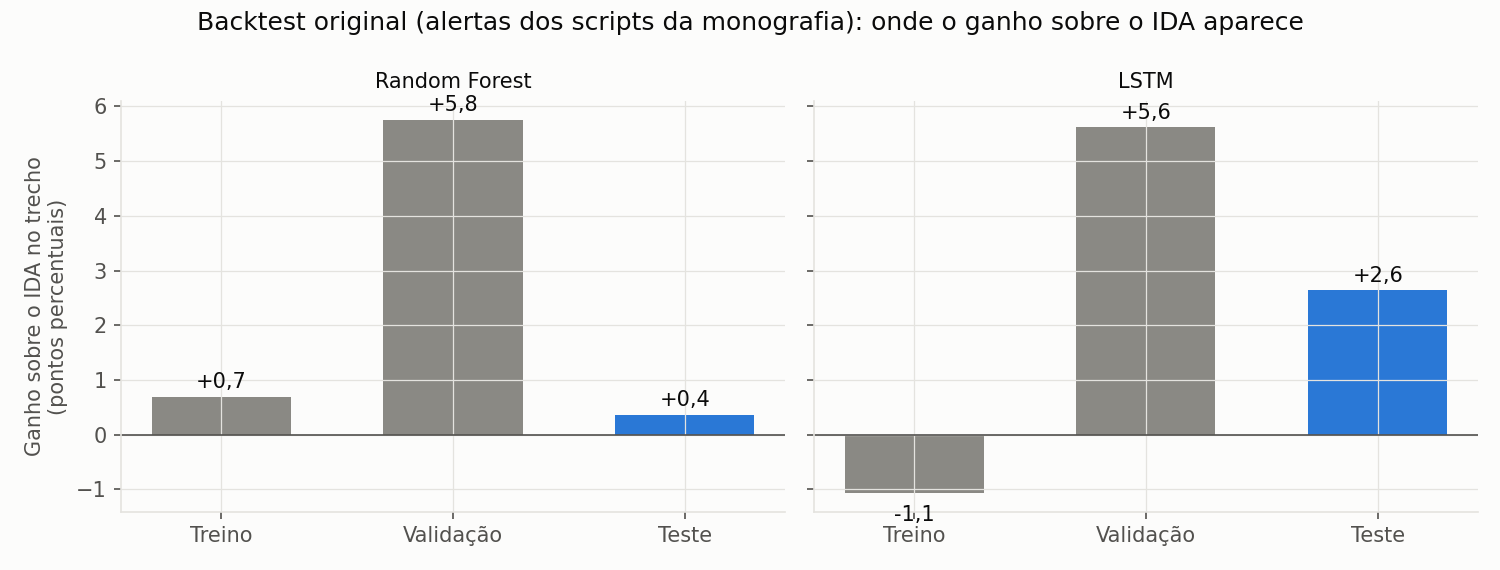

In [6]:
display(pd.read_csv(TAB / 'phase9_original_backtest_in_out_sample.csv').round(3))
display(Image(str(FIG / 'backtest_original_split.png')))